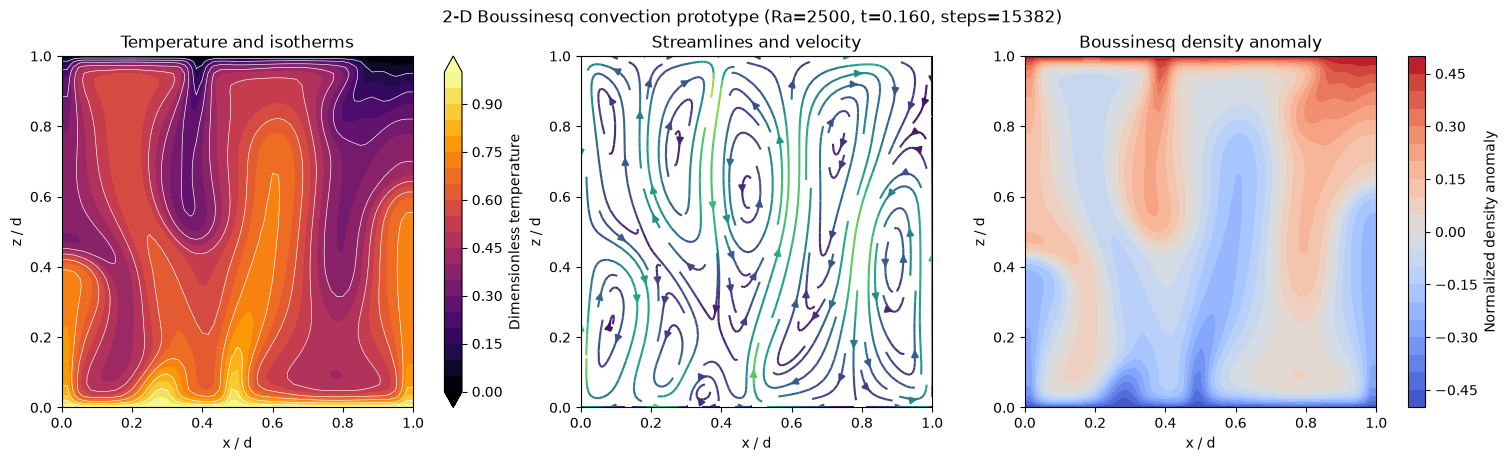

Finished: Ra=2500, dimensionless time=0.1600, steps=15382
max |u|=400; max |w|=545.3
Buoyancy force is upward for T>0.5 and downward for T<0.5.


In [10]:
"""Day 4: dimensionless 2-D Boussinesq convection demo.

Requires: numpy, matplotlib. Run: python day4_mantle_convection.py
Array convention is T[z, x], matching the preceding conduction model.
"""
import numpy as np
import matplotlib.pyplot as plt


def laplacian(a, dx, dz):
    return ((a[1:-1, 2:] - 2*a[1:-1, 1:-1] + a[1:-1, :-2]) / dx**2
            + (a[2:, 1:-1] - 2*a[1:-1, 1:-1] + a[:-2, 1:-1]) / dz**2)


def solve_streamfunction(rhs, dx, dz, iterations=180):
    """Solve ∇²ψ=rhs by Jacobi iteration with ψ=0 on all walls."""
    psi = np.zeros_like(rhs)
    dx2, dz2 = dx*dx, dz*dz
    denom = 2.0 * (dx2 + dz2)
    for _ in range(iterations):
        p = psi.copy()
        psi[1:-1, 1:-1] = (
            dz2*(p[1:-1, 2:] + p[1:-1, :-2])
            + dx2*(p[2:, 1:-1] + p[:-2, 1:-1])
            - dx2*dz2*rhs[1:-1, 1:-1]
        ) / denom
    return psi


def run():
    # Unit square, unit thermal diffusivity and ΔT; one moderate Ra value.
    n, ra, end_time = 61, 2500.0, 0.16
    x = np.linspace(0.0, 1.0, n)
    z = np.linspace(0.0, 1.0, n)
    dx = x[1] - x[0]
    dz = z[1] - z[0]
    X, Z = np.meshgrid(x, z)

    # Conductive profile plus a tiny smooth disturbance to seed circulation.
    T = 1.0 - Z + 0.015*np.sin(np.pi*X)*np.sin(np.pi*Z)
    T[0, :] = 1.0       # hot bottom
    T[-1, :] = 0.0      # cold top
    T[:, 0] = 1.0 - z   # insulating sidewalls are imposed through zero dT/dx
    T[:, -1] = 1.0 - z

    dt_diff = 0.20 / (2.0*(1.0/dx**2 + 1.0/dz**2))
    t, step = 0.0, 0
    while t < end_time:
        # Buoyancy anomaly is proportional to temperature under Boussinesq.
        # Curl of Stokes balance gives ∇²ψ = -Ra * ∂T/∂x.
        dTdx = np.gradient(T, dx, axis=1)
        psi = solve_streamfunction(-ra*dTdx, dx, dz)
        u = np.gradient(psi, dz, axis=0)
        w = -np.gradient(psi, dx, axis=1)
        speed = max(float(np.max(np.abs(u))), float(np.max(np.abs(w))), 1e-12)
        dt_adv = 0.35 * min(dx, dz) / speed
        dt = min(dt_diff, dt_adv, end_time-t)

        # First-order upwind advection; centered diffusion. Stable explicit step.
        tx = np.where(u[1:-1, 1:-1] >= 0,
                      (T[1:-1, 1:-1]-T[1:-1, :-2])/dx,
                      (T[1:-1, 2:]-T[1:-1, 1:-1])/dx)
        tz = np.where(w[1:-1, 1:-1] >= 0,
                      (T[1:-1, 1:-1]-T[:-2, 1:-1])/dz,
                      (T[2:, 1:-1]-T[1:-1, 1:-1])/dz)
        new = T.copy()
        new[1:-1, 1:-1] += dt*(-u[1:-1, 1:-1]*tx
                                -w[1:-1, 1:-1]*tz
                                +laplacian(T, dx, dz))
        # Fixed-temperature top/bottom; insulating left/right sidewalls.
        new[0, :] = 1.0
        new[-1, :] = 0.0
        new[:, 0] = new[:, 1]
        new[:, -1] = new[:, -2]
        T = new
        t += dt
        step += 1

    # Recompute final flow and dimensionalized density/buoyancy anomalies.
    psi = solve_streamfunction(-ra*np.gradient(T, dx, axis=1), dx, dz)
    u = np.gradient(psi, dz, axis=0)
    w = -np.gradient(psi, dx, axis=1)
    rho_anomaly = -(T - 0.5)  # normalized Δρ/(ρ0 α ΔT)

    np.savez("convection_results.npz", T=T, u=u, w=w, x=x, z=z)

    fig, ax = plt.subplots(1, 3, figsize=(15, 4.5), constrained_layout=True)
    levels = np.linspace(0, 1, 21)
    im = ax[0].contourf(X, Z, T, levels=levels, cmap="inferno", extend="both")
    ax[0].contour(X, Z, T, levels=np.linspace(0.1, 0.9, 9), colors="white", linewidths=.45)
    fig.colorbar(im, ax=ax[0], label="Dimensionless temperature")
    ax[0].set_title("Temperature and isotherms")

    skip = (slice(None, None, 3), slice(None, None, 3))
    ax[1].streamplot(x, z, u, w, color=np.hypot(u, w), cmap="viridis", density=1.1)
    ax[1].set_title("Streamlines and velocity")

    im2 = ax[2].contourf(X, Z, rho_anomaly, levels=21, cmap="coolwarm")
    fig.colorbar(im2, ax=ax[2], label="Normalized density anomaly")
    ax[2].set_title("Boussinesq density anomaly")

    for a in ax:
        a.set(xlabel="x / d", ylabel="z / d", xlim=(0, 1), ylim=(0, 1), aspect="equal")
    fig.suptitle(f"2-D Boussinesq convection prototype (Ra={ra:g}, t={t:.3f}, steps={step})")
    plt.savefig("day4_convection_result.png", dpi=180)
    plt.show()
    print(f"Finished: Ra={ra:g}, dimensionless time={t:.4f}, steps={step}")
    print(f"max |u|={np.max(np.abs(u)):.4g}; max |w|={np.max(np.abs(w)):.4g}")
    print("Buoyancy force is upward for T>0.5 and downward for T<0.5.")


if __name__ == "__main__":
    run()

Data loaded successfully!
Temperature shape: (61, 61)
Horizontal velocity shape: (61, 61)
Vertical velocity shape: (61, 61)
x shape: (61,)
z shape: (61,)

--- BASIC DATA CHECK ---
Temperature minimum = 0.0
Temperature maximum = 1.0
Horizontal velocity minimum = -323.77560515101095
Horizontal velocity maximum = 400.045179570833
Vertical velocity minimum = -545.2997961046323
Vertical velocity maximum = 487.52533836631295


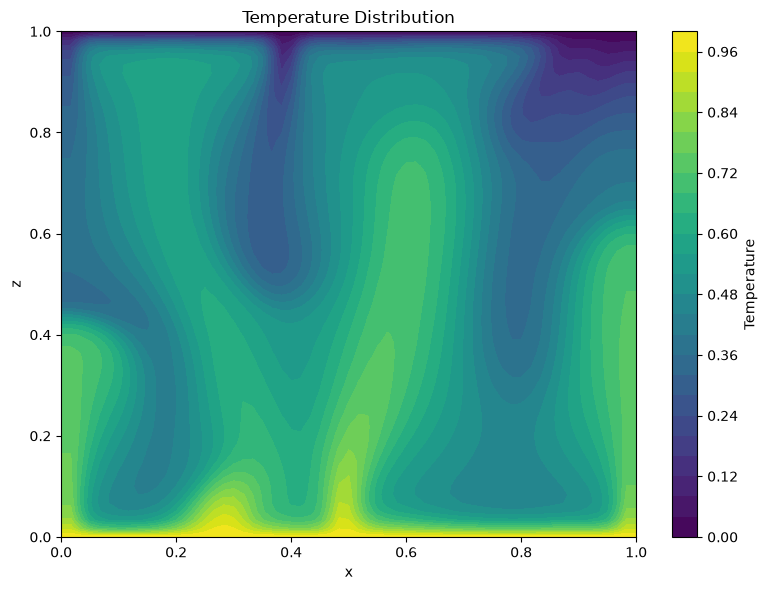

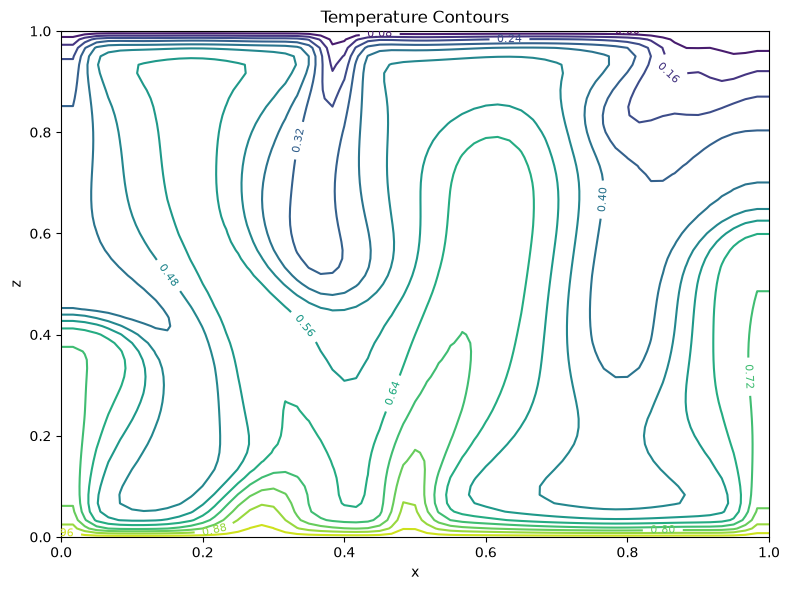

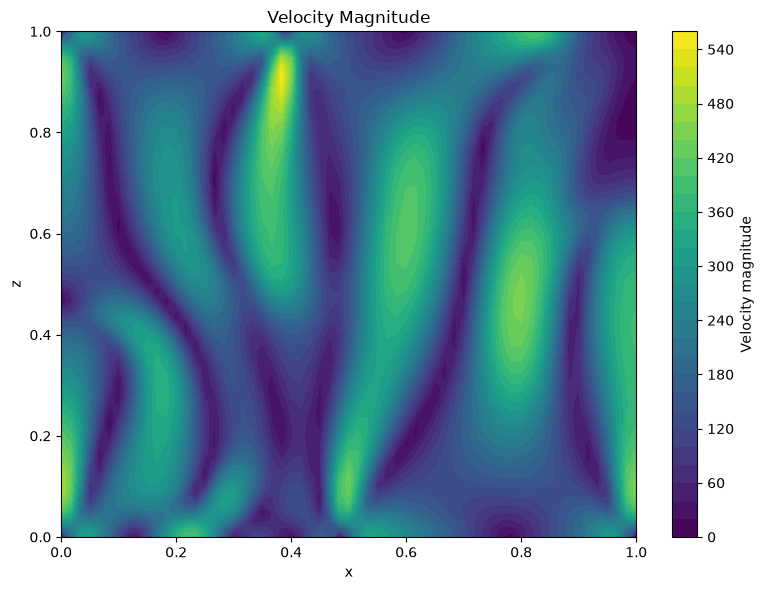

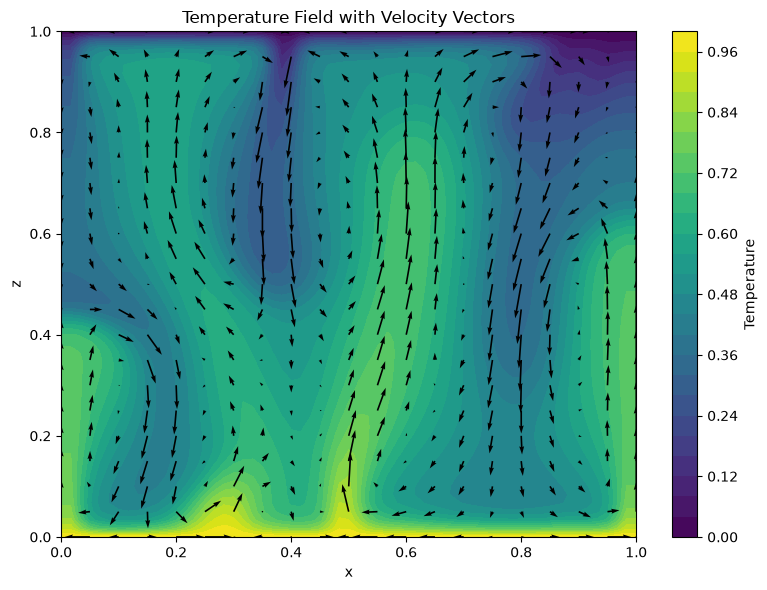

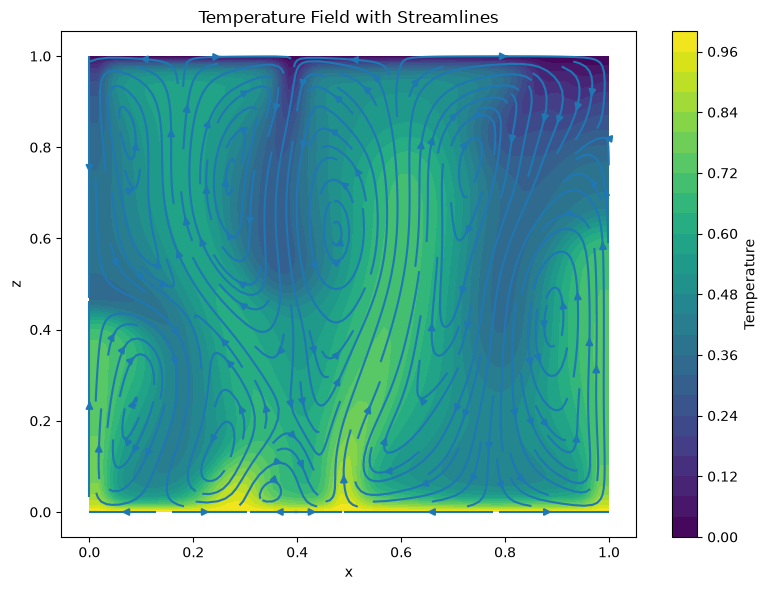

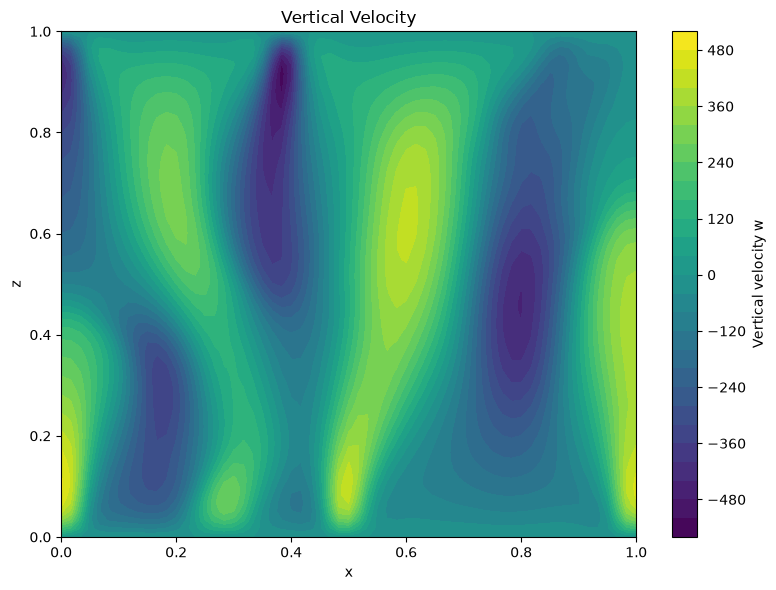

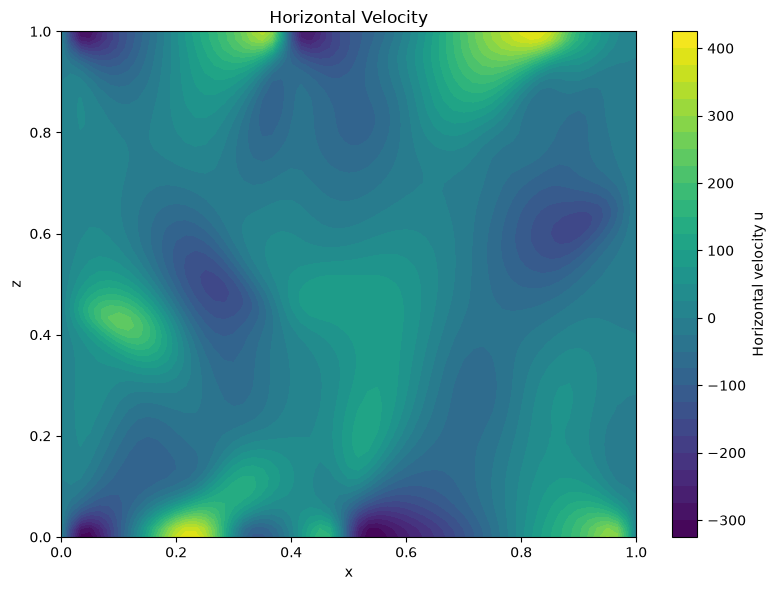


--- INCOMPRESSIBILITY CHECK ---
Maximum absolute divergence = 3.2741809263825417e-11


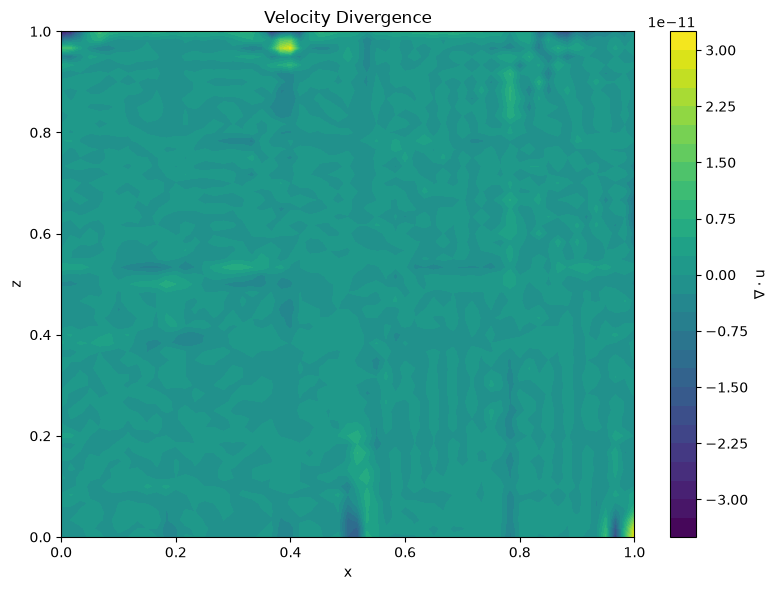


--- HOT/COLD REGION ANALYSIS ---
Mean temperature = 0.5151041927321665
Average vertical velocity in hot regions = 139.58718044741218
Average vertical velocity in cold regions = -143.0170034003152


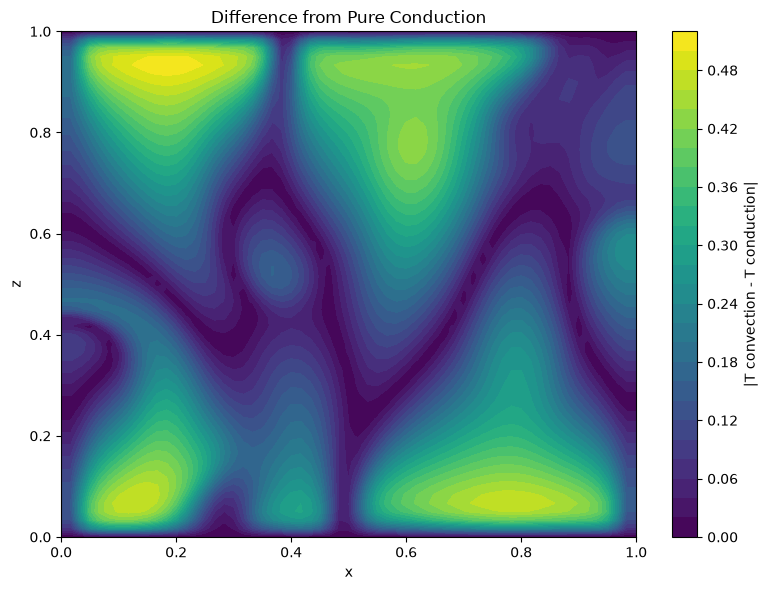

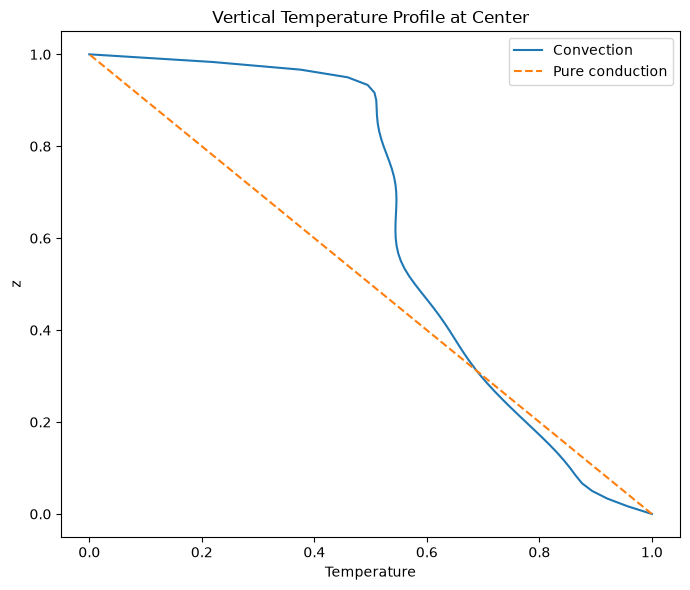


       PERSON 3 ANALYSIS
Temperature range:
0.0 to 1.0

Maximum velocity magnitude:
549.6488404841707

Maximum absolute divergence:
3.2741809263825417e-11

Average vertical velocity in hot regions:
139.58718044741218

Average vertical velocity in cold regions:
-143.0170034003152

Analysis complete!


In [1]:
import numpy as np
import matplotlib.pyplot as plt


# ============================================================
# 1. LOAD DATA FROM PERSON 2
# ============================================================

data = np.load("convection_results.npz")

T = data["T"]
u = data["u"]
w = data["w"]
x = data["x"]
z = data["z"]

# Streamfunction may or may not be available
if "psi" in data:
    psi = data["psi"]
else:
    psi = None


print("Data loaded successfully!")

print("Temperature shape:", T.shape)
print("Horizontal velocity shape:", u.shape)
print("Vertical velocity shape:", w.shape)
print("x shape:", x.shape)
print("z shape:", z.shape)


# ============================================================
# 2. CREATE 2-D GRID
# ============================================================

X, Z = np.meshgrid(x, z)


# ============================================================
# 3. BASIC DATA CHECK
# ============================================================

print("\n--- BASIC DATA CHECK ---")

print("Temperature minimum =", np.min(T))
print("Temperature maximum =", np.max(T))

print("Horizontal velocity minimum =", np.min(u))
print("Horizontal velocity maximum =", np.max(u))

print("Vertical velocity minimum =", np.min(w))
print("Vertical velocity maximum =", np.max(w))


# ============================================================
# 4. TEMPERATURE DISTRIBUTION
# ============================================================

plt.figure(figsize=(8, 6))

contour = plt.contourf(
    X,
    Z,
    T,
    levels=30
)

plt.colorbar(contour, label="Temperature")

plt.xlabel("x")
plt.ylabel("z")
plt.title("Temperature Distribution")

plt.tight_layout()
plt.show()


# ============================================================
# 5. TEMPERATURE CONTOURS
# ============================================================

plt.figure(figsize=(8, 6))

contours = plt.contour(
    X,
    Z,
    T,
    levels=15
)

plt.clabel(contours, inline=True, fontsize=8)

plt.xlabel("x")
plt.ylabel("z")
plt.title("Temperature Contours")

plt.tight_layout()

plt.show()


# ============================================================
# 6. VELOCITY MAGNITUDE
# ============================================================

velocity_magnitude = np.sqrt(u**2 + w**2)

plt.figure(figsize=(8, 6))

contour = plt.contourf(
    X,
    Z,
    velocity_magnitude,
    levels=30
)

plt.colorbar(contour, label="Velocity magnitude")

plt.xlabel("x")
plt.ylabel("z")
plt.title("Velocity Magnitude")

plt.tight_layout()

plt.show()


# ============================================================
# 7. VELOCITY VECTORS
# ============================================================

plt.figure(figsize=(8, 6))

# Reduce number of arrows so the plot is readable
step = max(1, len(x) // 20)

plt.contourf(X, Z, T, levels=30)
plt.colorbar(label="Temperature")

plt.quiver(
    X[::step, ::step],
    Z[::step, ::step],
    u[::step, ::step],
    w[::step, ::step]
)

plt.xlabel("x")
plt.ylabel("z")
plt.title("Temperature Field with Velocity Vectors")

plt.tight_layout()

plt.show()


# ============================================================
# 8. STREAMLINES
# ============================================================

plt.figure(figsize=(8, 6))

plt.contourf(
    X,
    Z,
    T,
    levels=30
)

plt.colorbar(label="Temperature")

plt.streamplot(
    x,
    z,
    u,
    w,
    density=1.5
)

plt.xlabel("x")
plt.ylabel("z")
plt.title("Temperature Field with Streamlines")

plt.tight_layout()
plt.show()


# ============================================================
# 9. VERTICAL VELOCITY
# ============================================================

plt.figure(figsize=(8, 6))

contour = plt.contourf(
    X,
    Z,
    w,
    levels=30
)

plt.colorbar(contour, label="Vertical velocity w")

plt.xlabel("x")
plt.ylabel("z")
plt.title("Vertical Velocity")

plt.tight_layout()

plt.show()


# ============================================================
# 10. HORIZONTAL VELOCITY
# ============================================================

plt.figure(figsize=(8, 6))

contour = plt.contourf(
    X,
    Z,
    u,
    levels=30
)

plt.colorbar(contour, label="Horizontal velocity u")

plt.xlabel("x")
plt.ylabel("z")
plt.title("Horizontal Velocity")

plt.tight_layout()

plt.show()


# ============================================================
# 11. CHECK INCOMPRESSIBILITY
# ============================================================

du_dx = np.gradient(u, x, axis=1)
dw_dz = np.gradient(w, z, axis=0)

divergence = du_dx + dw_dz

maximum_divergence = np.max(np.abs(divergence))

print("\n--- INCOMPRESSIBILITY CHECK ---")

print(
    "Maximum absolute divergence =",
    maximum_divergence
)


plt.figure(figsize=(8, 6))

contour = plt.contourf(
    X,
    Z,
    divergence,
    levels=30
)

plt.colorbar(contour, label="∇ · u")

plt.xlabel("x")
plt.ylabel("z")
plt.title("Velocity Divergence")

plt.tight_layout()


plt.show()


# ============================================================
# 12. HOT AND COLD REGION ANALYSIS
# ============================================================

mean_temperature = np.mean(T)

hot_region = T > mean_temperature
cold_region = T < mean_temperature

average_w_hot = np.mean(w[hot_region])
average_w_cold = np.mean(w[cold_region])

print("\n--- HOT/COLD REGION ANALYSIS ---")

print("Mean temperature =", mean_temperature)

print(
    "Average vertical velocity in hot regions =",
    average_w_hot
)

print(
    "Average vertical velocity in cold regions =",
    average_w_cold
)


# ============================================================
# 13. PURE CONDUCTION COMPARISON
# ============================================================

# For the nondimensional setup:
# bottom temperature = 1
# top temperature = 0
#
# and z increases upward from 0 to 1.
#
# Pure conduction solution:
# T = 1 - z

T_conduction = 1 - Z

temperature_difference = np.abs(
    T - T_conduction
)


plt.figure(figsize=(8, 6))

contour = plt.contourf(
    X,
    Z,
    temperature_difference,
    levels=30
)

plt.colorbar(
    contour,
    label="|T convection - T conduction|"
)

plt.xlabel("x")
plt.ylabel("z")
plt.title("Difference from Pure Conduction")

plt.tight_layout()



plt.show()


# ============================================================
# 14. CENTER VERTICAL TEMPERATURE PROFILE
# ============================================================

middle_x = len(x) // 2

plt.figure(figsize=(7, 6))

plt.plot(
    T[:, middle_x],
    z,
    label="Convection"
)

plt.plot(
    1 - z,
    z,
    "--",
    label="Pure conduction"
)

plt.xlabel("Temperature")
plt.ylabel("z")

plt.title("Vertical Temperature Profile at Center")

plt.legend()

plt.tight_layout()


plt.show()


# ============================================================
# 15. STREAMFUNCTION IF AVAILABLE
# ============================================================

if psi is not None:

    plt.figure(figsize=(8, 6))

    contour = plt.contourf(
        X,
        Z,
        psi,
        levels=30
    )

    plt.colorbar(
        contour,
        label="Streamfunction ψ"
    )

    plt.xlabel("x")
    plt.ylabel("z")

    plt.title("Streamfunction")

    plt.tight_layout()
    
plt.show()


# ============================================================
# 16. FINAL SUMMARY
# ============================================================

print("\n====================================")
print("       PERSON 3 ANALYSIS")
print("====================================")

print("Temperature range:")
print(np.min(T), "to", np.max(T))

print("\nMaximum velocity magnitude:")
print(np.max(velocity_magnitude))

print("\nMaximum absolute divergence:")
print(maximum_divergence)

print("\nAverage vertical velocity in hot regions:")
print(average_w_hot)

print("\nAverage vertical velocity in cold regions:")
print(average_w_cold)

print("\nAnalysis complete!")